In [3]:
# imports
%matplotlib widget
import ipywidgets as widgets
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import scipy.integrate as spintg
import scipy.interpolate as spintp

### Kinematics
From the given problem, the kinematics derived are the following:
$$
\begin{aligned}
x(\theta_l,\theta_r) &= \frac{r_m(\theta_l+\theta_r) - d_y}{2} \\
y(\theta_l,\theta_r) &= \frac{r_m(\theta_l-\theta_r) + d_y}{2} \\
\dot{x}(\dot\theta_l,\dot\theta_r) &= \frac{r_m}{2}\left(\dot\theta_l+\dot\theta_r\right) \\
\dot{y}(\dot\theta_l,\dot\theta_r) &= \frac{r_m}{2}\left(\dot\theta_l-\dot\theta_r\right)
\end{aligned}
$$

I considered a model in which the tool head is a point mass, and by checking the tool head's position at a hypothetical $\theta_l = 0$ and $\theta_r = 0$ and using intuition I was able to determine the effects of rotation of the xy position of the tool head. Notice that I also used $d_x$ and $d_y$ in my formulation to stay as close as possible to the physical system. Below you can find a (very) simple interactive graph that shows how our tool head moves if only one of the motors is active at a time.

In [6]:
def calculate_position(theta_l, theta_r, d_x, d_y, r_m):
    x = ((r_m * (theta_l + theta_r) - d_y)) / 2
    y = ((r_m * (theta_l - theta_r) + d_y)) / 2

    return x, y

interactive(children=(FloatSlider(value=100.0, description='theta_l', max=400.0), FloatSlider(value=100.0, des…

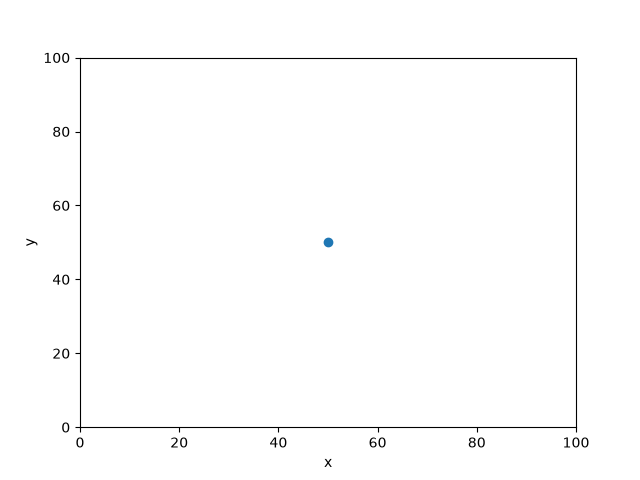

In [7]:
# Here I define my static variables. They can be changed but are chosen for convenience in plotting
# I am trying to keep the plots as general and customizable as possible!
d_x = 100.0
d_y = 100.0
theta_l_init = 100.0
theta_r_init = 100.0
r_m = 1.0

x, y = calculate_position(theta_l_init, theta_r_init, d_x, d_y, r_m)

fig, ax = plt.subplots()

ax.set(xlim=(0, d_x), ylim=(0, d_y))
ax.set_xlabel("x")
ax.set_ylabel("y")

plot = ax.scatter(x, y) # Create INITIAL scatter plot

@widgets.interact(
    theta_l=widgets.FloatSlider(min=0.0, max=400.0, value=theta_l_init, step=0.1),
    theta_r=widgets.FloatSlider(min=0.0, max=400.0, value=theta_r_init, step=0.1)
)
def update_position(theta_l, theta_r):
    
    x, y = calculate_position(theta_l, theta_r, d_x, d_y, r_m)

    print(x, y)

    plot.set_offsets([[x, y]])

    fig.canvas.draw_idle()

### 

In [4]:
K_M = 1.0
m = 1.0
J_m = 1.0
L_m = 1.0
R_m = 1.0
r_b = 0.5
mu_r = 0.2
mu_l_x = 0.2
mu_l_y = 0.2

f1 = mu_r * r_m**2 / (r_b**2)
f2 = r_m**2 / 2 * (mu_l_x + mu_l_y)
f3 = r_m**2 / 2 * (mu_l_x - mu_l_y)

C_m = r_m / (r_m * r_m * m + 2 * J_m)

A = np.array([
    [0, 1, 0, 0, 0, 0],                             #position x
    [0, -2*(C_m / r_m)* (4*f1 + f2 + f3), C_m * K_M, 0, 0, 0],                           #velocity x
    [0, -2 * K_M / (r_m * L_m), -R_m / L_m, 0, 0, 0], #current x
    [0, 0, 0, 0, 1, 0],                             # position y
    [0, 0, 0, 0, -2*(C_m / r_m)* (2*f1 + f2 - f3), K_M*C_m],                           # velocity y
    [0, 0, 0, 0, -2 * K_M / (r_m * L_m), -R_m / L_m]  #current y
])

B = np.array([
    [0, 0],
    [0, 0],
    [1/L_m, 0],
    [0, 0],
    [0, 0],
    [0, 1/L_m]
])


C = np.array([
    [1, 0, 0, 0, 0, 0],
    [0, 0, 0, 1, 0, 0]
])

CAAB = C @ A @ A @ B
CAAA = C @ A @ A @ A
print(CAAB)
print(CAAA)

[[0.33333333 0.        ]
 [0.         0.33333333]]
[[ 0.          4.47111111 -1.08888889  0.          0.          0.        ]
 [ 0.          0.          0.          0.          0.77333333 -0.73333333]]


In [5]:
a = 40
b = 30
omega = 1
delta = np.pi / 2
t_start = 0
t_fin = np.pi * 2 / omega # value at which I've done a full loop

t = np.linspace(t_start, t_fin, 2000) # timepoints
delta_t = t[1] - t[0]
# My desired trajectory, an ellipse
y = np.array([
    a * np.sin(omega * t + delta),
    b * np.sin(t)
])

print(y.shape)

dydt = np.array([
    a * omega * np.cos(omega * t + delta),
    b * np.cos(t)
])
dydt_2 = np.array([
    -a * omega**2 * np.sin(omega * t + delta),
    -b * np.sin(t)
])
dydt_3 = np.array([
    -a * omega**3 * np.cos(omega * t + delta),
    -b * np.cos(t)
])

x = np.array([
    a * np.sin(omega * t + delta),
    dydt[0],
    (1/(K_M*C_m)) * dydt_2[0] + (2 / (K_M*r_m)) * (4*f1 + f2 + f3) * dydt[0], #current calculated in terms of trajectory
    b * np.sin(t),
    dydt[1],
    (1/(K_M*C_m)) * dydt_2[1] + (2 / (K_M*r_m)) * (2*f1 + f2 - f3) * dydt[1], #current calculated in terms of trajectory
])
print(x.shape)
CAAB_inv = np.linalg.pinv(CAAB)

u = CAAB_inv @ (dydt_3 - CAAA @ x)
print(u[:, 0])

(2, 2000)
(6, 2000)
[-392.   78.]


In [6]:
# Time to see if it works!
x0 = x[:, 0]
print(x0)
print(y[:, 0])

# ODE solver needs a function that can return a value for any time, 
# even not belonging of my linspace t
u_interpolate = spintp.interp1d(t, u)

def system_dynamics(t, state):
    u_now = u_interpolate(t)
    return A @ state + B @ u_now

solution = spintg.solve_ivp(system_dynamics, (t_start, t_fin), x0, t_eval=t, method='RK45')

y_calculated = C @ solution.y # This is my trajectory

[ 4.0000000e+01  2.4492936e-15 -1.2000000e+02  0.0000000e+00
  3.0000000e+01  1.0800000e+02]
[40.  0.]


In [7]:
def plot_q14():
    fig, axs = plt.subplots(2, 2, figsize=(12, 12))
    
    # 1. Top-Left: 2D Ellipse Tracking (Target vs Actual)
    desired_trajectory = axs[0, 0].plot(y[0], y[1], 'r--', label='Target Ellipse', linewidth=0.2)
    calculated_trajectory, = axs[0, 0].plot([], [], 'b-', label='Actual Trajectory', alpha=0.8)
    axs[0, 0].set_title('2D Tracking')
    axs[0, 0].set_xlabel('X Position')
    axs[0, 0].set_ylabel('Y Position')
    axs[0, 0].legend()
    axs[0, 0].grid(True)
    axs[0, 0].set_aspect('equal') # Keeps the ellipse from distorting
    
    # 2. Top-Right: X-Axis Tracking Over Time
    axs[0, 1].plot(t, y[0], 'r--', label='desired X', linewidth=2)
    calculated_x, = axs[0, 1].plot([], [], 'b-', label='calculated X')
    axs[0, 1].set_title('X-Axis position in time')
    axs[0, 1].set_xlabel('Time')
    axs[0, 1].set_ylabel('Position')
    axs[0, 1].legend()
    axs[0, 1].grid(True)
    
    # 3. Bottom-Left: Y-Axis Tracking Over Time
    axs[1, 0].plot(t, y[1], 'r--', label='Target Y', linewidth=2)
    calculated_y, = axs[1, 0].plot([], [], 'b-', label='Actual Y')
    axs[1, 0].set_title('Y-Axis Position vs Time')
    axs[1, 0].set_xlabel('Time (s)')
    axs[1, 0].set_ylabel('Position')
    axs[1, 0].legend()
    axs[1, 0].grid(True)
    
    input_1, = axs[1, 1].plot([], [], label='Voltage U1', color='purple')
    input_2, = axs[1, 1].plot([], [], label='Voltage U2', color='orange')
    axs[1, 1].set_title('Required Control Inputs (Voltages)')
    axs[1, 1].set_xlabel('Time (s)')
    axs[1, 1].set_ylabel('Voltage')
    axs[1, 1].legend()
    axs[1, 1].grid(True)
    
    def init_graphs_q14():
        calculated_trajectory.set_data([], [])
        calculated_x.set_data([], [])
        calculated_y.set_data([], [])
        input_1.set_data([], [])
        input_2.set_data([], [])
        return calculated_trajectory, calculated_x, calculated_y, input_1, input_2
    
    def update_graphs_q14(timestep):
        calculated_trajectory.set_data(y_calculated[0, :timestep], y_calculated[1, :timestep])
        calculated_x.set_data(k[:timestep], y_calculated[0, :timestep])
        calculated_y.set_data(k[:timestep], y_calculated[1, :timestep])
        input_1.set_data(t[:timestep], u[0, :timestep])
        input_2.set_data(t[:timestep], u[1, :timestep])
        return calculated_trajectory, calculated_x, calculated_y, input_1, input_2
    
    plt.tight_layout()
    
    ani = animation.FuncAnimation(fig, update_graphs_q14, frames=len(t), init_func=init_graphs_q14, 
                                  interval=1, blit=True)
    
    plt.show()

In [8]:
#plot_q14()

In [9]:
# Setting the parameters
rho_f = 1e3
c_f = 1.5e3
kappa_f = 0.2
G_env = 0.016
G_plate = 0.48
a = 0.0004
T_env = 23.0
T_plate = 80.0

r = 0.02 # radius of circle
L = 2 * np.pi * r # circumference of line trajectory
num_blocks = 2000 # number of sub-units to split length in
num_timesteps = 2000 + 2000
v = 0.05 # deposition speed
dx = L / num_blocks
dt = dx / v # one block extra is lain every timestep
T_fill = 200.0 # FIlament printed at 200 Celsius

T = np.full((num_blocks, num_timesteps), np.nan)
T[0,0] = T_fill
print(T)

for k in range(num_timesteps-1):
    n = min(1 + k, num_blocks)
    Tt = T[:n, k]
    laplacian = np.empty(n) # this will contain the second order space derivative of T
    if n == 1:
        laplacian[0] = 0 # no other block to consider as there is only one
    else:
        laplacian[1:-1] = Tt[2:] - 2 * Tt[1:-1] + Tt[:-2]
        laplacian[0] = 2 * (Tt[1] - Tt[0]) # boundary condition
        laplacian[-1] = Tt[-2] - 2 * Tt[-1] + T_fill # At the boundary, I am assuming the end of filament is attached to the nozzle
        if n == num_blocks:
            laplacian[0]  = Tt[1]  - 2*Tt[0]  + Tt[-1]
            laplacian[-1] = Tt[-2] - 2*Tt[-1] + Tt[0]
    extern = (1/a**2) * (0.75 * G_env * (T_env - Tt) + 0.25 * G_plate * (T_plate - Tt))

    T[:n, k+1] = T[:n, k] + (dt / (rho_f * c_f)) * ((kappa_f / dx**2) * laplacian + extern)

    if n < num_blocks:
        T[n, k+1] = T_fill



[[200.  nan  nan ...  nan  nan  nan]
 [ nan  nan  nan ...  nan  nan  nan]
 [ nan  nan  nan ...  nan  nan  nan]
 ...
 [ nan  nan  nan ...  nan  nan  nan]
 [ nan  nan  nan ...  nan  nan  nan]
 [ nan  nan  nan ...  nan  nan  nan]]


In [10]:
def plots_q16():
    time = np.arange(num_timesteps) * dt
    pos = np.arange(num_blocks) * dx
    
    fig, axs = plt.subplots(2, 1)
    m = axs[0].pcolormesh(time, pos, np.ma.masked_invalid(T), cmap="inferno", shading="auto")
    fig.colorbar(m, label="Temperature (Celsius)")
    axs[0].set_xlabel("time (s)")
    axs[0].set_ylabel("position along filament (m)")
    
    for i in (0, num_blocks // 4, num_blocks // 2, num_blocks - 1):
        axs[1].plot(time, T[i], label=f"cell {i}")
    axs[1].set_xlabel("time (s)")
    axs[1].set_ylabel("Temperature (Celsius)")
    axs[1].legend()
    
    plt.show()

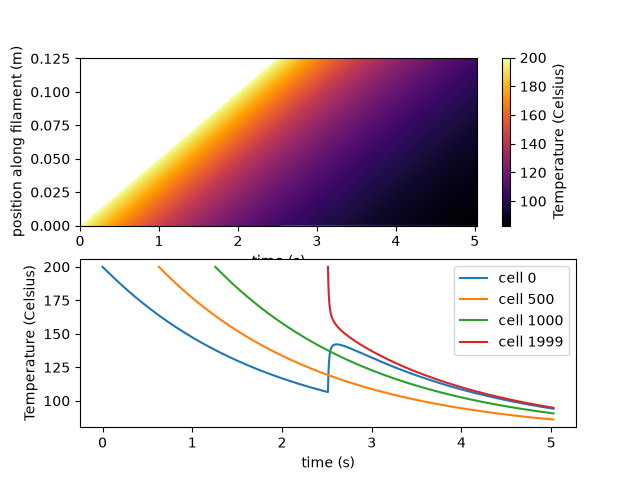

In [14]:
plots_q16()

In [12]:
def plot_q16_over_time(step=20):
    fig, ax = plt.subplots()

    theta = 2*np.pi * np.arange(num_blocks) / num_blocks
    x_pts, y_pts = r*np.cos(theta), r*np.sin(theta)

    sc = ax.scatter(x_pts, y_pts, c=np.full(num_blocks, T_env),
                    cmap="inferno", vmin=T_env, vmax=T_fill, s=8)
    sc.cmap.set_bad(alpha=0)
    fig.colorbar(sc, label="Temperature (Celsius)")
    ax.set_aspect("equal")
    title = ax.set_title("t = 0s")
    plt.tight_layout()

    def update(k):
        sc.set_array(np.ma.masked_invalid(T[:, k]))
        title.set_text(f"t = {k*dt:.2f} s")
        return sc, title

    an = animation.FuncAnimation(fig, update, frames=range(0, num_timesteps, step),
                                  interval=30, blit=False)
    return an

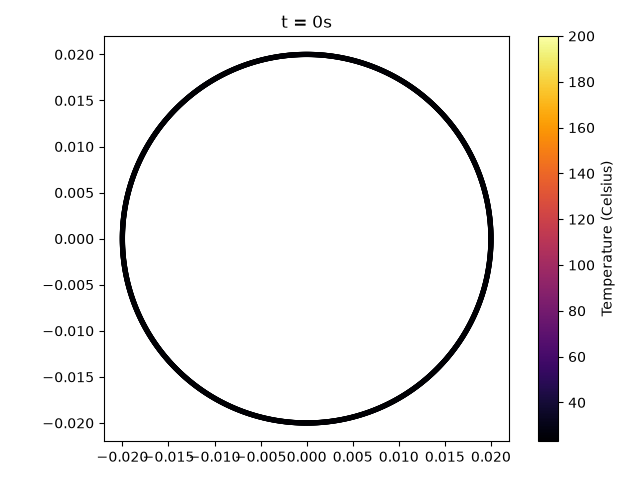

In [13]:
an = plot_q16_over_time()